In [1]:
import pymongo as pm
import pandas as pd
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import numpy as np

client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)

In [2]:
db= client['carsharing']
pb_coll = db['PermanentBookings']
ap_coll = db['ActiveParkings']
ab_coll = db['ActiveParkings']
pp_coll = db['PermanentParkings']

In [3]:
start = int(datetime(2017, 11, 1, tzinfo=timezone.utc).timestamp())
end   = int(datetime(2018, 2, 1, tzinfo=timezone.utc).timestamp())

cities = ["Torino","Columbus","Frankfurt"]

In [4]:
def load_wtime(coll, city):
    pipe = [
        {"$match": {"city": city, "init_time": {"$gte": start, "$lt": end}}},
        {"$project": {"_id": 0, 
                      "init_time": 1,
                      "duration": {"$subtract": ["$final_time", "$init_time"]},
                      "day":      {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                        "week":     {"$isoWeek": "$init_date"},
                        "iso_year": {"$isoWeekYear": "$init_date"},
                        "dow":      {"$isoDayOfWeek": "$init_date"},
                        "hour":     {"$hour": "$init_date"},}}           
    ]
        
    df = pd.DataFrame(db[coll].aggregate(pipe, allowDiskUse=True))
    df["duration_min"] = df["duration"]/60
    return df

In [6]:
bookings = {c: load_wtime("PermanentBookings", c) for c in cities}
parkings = {c: load_wtime("PermanentParkings", c) for c in cities}

In [7]:
def best_zone(x, q=0.9, log=True):
    """
    Zone la plus dense : le plus petit intervalle [a, b] qui contient une fraction q
    des échantillons (sur la ECDF : F(b) - F(a) = q).
    log=True : la largeur est mesurée en log(durée), adapté aux durées très étalées
               -> on enlève à la fois les durées très courtes et la longue traîne.
               Les durées <= 0 (invalides) sont retirées avant le calcul.
    """
    x = np.sort(np.asarray(x, dtype=float))
    if log:
        x = x[x > 0]
    t = np.log(x) if log else x
    n = len(x)
    k = int(np.ceil(q * n))                 # nb de points à garder
    widths = t[k - 1:] - t[:n - k + 1]      # largeur de chaque fenêtre de k points consécutifs
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=0.9, col="duration_min", log=True):
    """Garde uniquement les lignes dont la durée est dans la zone la plus dense."""
    a, b = best_zone(df[col].values, q, log)
    return df[df[col].between(a, b)].copy(), (a, b)


Q = 0.90   # fraction de la ECDF à conserver

raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in cities:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])
        print(f"{kind:9s} {c:10s} zone = [{a:7.1f}, {b:8.1f}] min -> {n1}/{n0} gardés ({n1/n0:.1%})")

bookings_f = filtered["bookings"]
parkings_f = filtered["parkings"]

bookings  Torino     zone = [    0.8,     38.0] min -> 238053/264503 gardés (90.0%)
bookings  Columbus   zone = [    0.8,     44.0] min -> 47679/52976 gardés (90.0%)
bookings  Frankfurt  zone = [    0.8,     60.1] min -> 131902/146557 gardés (90.0%)
parkings  Torino     zone = [    0.8,    410.4] min -> 238088/264542 gardés (90.0%)
parkings  Columbus   zone = [    1.5,   1719.7] min -> 47631/52923 gardés (90.0%)
parkings  Frankfurt  zone = [    0.8,    432.1] min -> 132169/146854 gardés (90.0%)


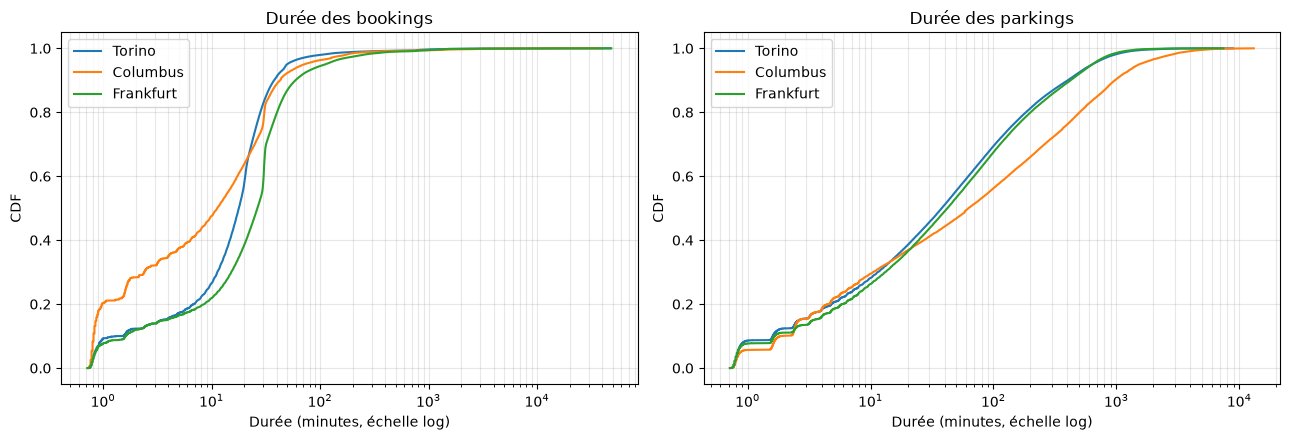

In [8]:
def plot_cdf(data_dict, title, ax):
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        x = x[x > 0]                                  # nécessaire pour l'axe log
        y = np.arange(1, len(x)+1) / len(x)
        ax.plot(x, y, label=city)
    ax.set_xscale("log")
    ax.set_xlabel("Durée (minutes, échelle log)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings, "Durée des bookings", axes[0])
plot_cdf(parkings, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()

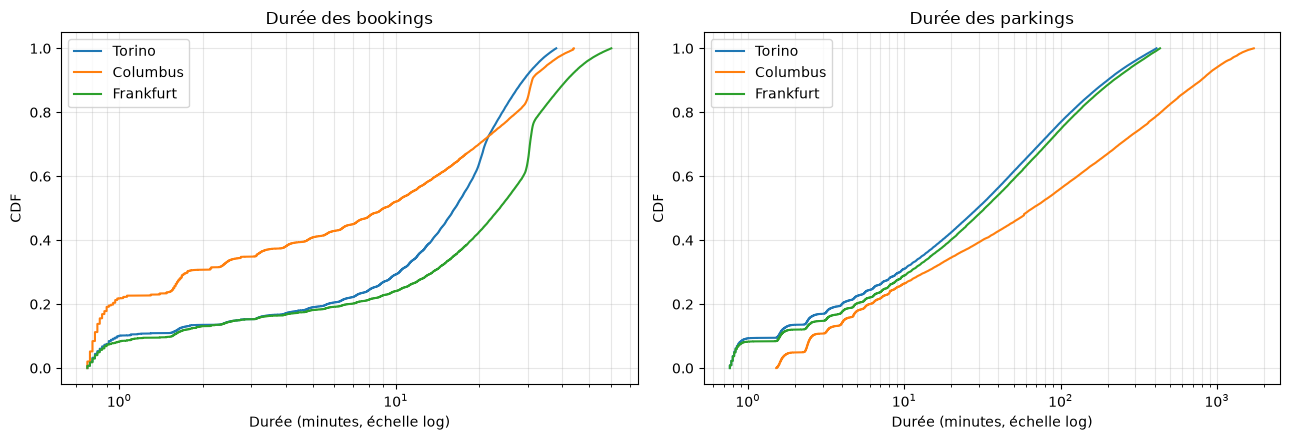

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings_f, "Durée des bookings", axes[0])
plot_cdf(parkings_f, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()